In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/customer churn.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (10300, 10)


,Customer_ID,Gender,Region,Subscription_Plan,Payment_Method,Age,Days_Since_Last_Login,Customer_Service_Calls,Monthly_Spend,Churn
0,10001,Male,East,Basic,PayPal,27.0,27,1,61.08,0
1,10002,Unknown,West,Pro,PayPal,55.0,146,2,73.09,0
2,10003,Female,West,Pro,E-Wallet,NaN,147,2,116.30,1
3,10004,Female,south,Basic,Credit Card,NaN,34,1,0.58,1
4,10005,Male,North,Basic,Crypto,30.0,146,3,46.35,1


In [2]:
print("Dataset Information")
df.info()

print("\nMissing Values")
print(df.isnull().sum())

print("\nDuplicate Rows")
print(df.duplicated().sum())

print("\nStatistical Summary")
display(df.describe())

print("\nCategorical Values")
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10300 entries, 0 to 10299
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer_ID             10300 non-null  int64  
 1   Gender                  10300 non-null  object 
 2   Region                  10300 non-null  object 
 3   Subscription_Plan       10300 non-null  object 
 4   Payment_Method          9575 non-null   object 
 5   Age                     9267 non-null   float64
 6   Days_Since_Last_Login   10300 non-null  int64  
 7   Customer_Service_Calls  10300 non-null  int64  
 8   Monthly_Spend           9786 non-null   float64
 9   Churn                   10300 non-null  int64  
dtypes: float64(2), int64(4), object(4)
memory usage: 804.8+ KB

Missing Values
Customer_ID                  0
Gender                       0
Region                       0
Subscription_Plan            0
Payment_Method             725


,Customer_ID,Age,Days_Since_Last_Login,Customer_Service_Calls,Monthly_Spend,Churn
count,10300.000000,9267.000000,10300.000000,10300.000000,9786.000000,10300.000000
mean,14859.237864,33.521852,89.449903,1.787379,300.093737,0.762039
std,2959.197492,11.514686,52.088510,1.363470,4733.134612,0.425856
min,10001.000000,-10.000000,0.000000,-1.000000,-10.000000,0.000000
25%,12275.750000,26.000000,44.000000,1.000000,26.275000,1.000000
50%,14850.500000,33.000000,90.000000,2.000000,66.355000,1.000000
75%,17425.250000,40.000000,135.000000,3.000000,115.915000,1.000000
max,20000.000000,150.000000,179.000000,9.000000,99999.990000,1.000000



Categorical Values

Gender:
Gender
Male          4187
Female        4088
Non-Binary    1035
Unknown        990
Name: count, dtype: int64

Region:
Region
South    2350
East     2334
West     2330
North    2285
south     257
west      257
east      252
north     235
Name: count, dtype: int64

Subscription_Plan:
Subscription_Plan
Basic    4517
Pro      2886
Plus     1862
BASIC     486
PRO       330
PLUS      219
Name: count, dtype: int64

Payment_Method:
Payment_Method
Crypto         2432
PayPal         2392
Credit Card    2380
E-Wallet       2371
NaN             725
Name: count, dtype: int64


In [3]:
before_report = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Missing Cells",
        "Duplicate Rows"
    ],
    "Before Cleaning": [
        len(df),
        len(df.columns),
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ]
})

display(before_report)

,Metric,Before Cleaning
0,Total Rows,10300
1,Total Columns,10
2,Missing Cells,2272
3,Duplicate Rows,300


In [4]:
print("Before removing duplicates:", df.shape)

df = df.drop_duplicates()

print("After removing duplicates:", df.shape)
print("Duplicates remaining:", df.duplicated().sum())

Before removing duplicates: (10300, 10)
After removing duplicates: (10000, 10)
Duplicates remaining: 0


In [5]:
categorical_columns = [
    "Gender",
    "Region",
    "Subscription_Plan",
    "Payment_Method"
]

for col in categorical_columns:
    df[col] = df[col].str.strip().str.title()

for col in categorical_columns:
    print(col, df[col].unique())

Gender ['Male' 'Unknown' 'Female' 'Non-Binary']
Region ['East' 'West' 'South' 'North']
Subscription_Plan ['Basic' 'Pro' 'Plus']
Payment_Method ['Paypal' 'E-Wallet' 'Credit Card' 'Crypto' nan]


In [6]:
# Invalid ages
df.loc[
    (df["Age"] < 0) | (df["Age"] > 100),
    "Age"
] = np.nan

# Negative monthly spending
df.loc[df["Monthly_Spend"] < 0, "Monthly_Spend"] = np.nan

# Negative customer service calls
df.loc[
    df["Customer_Service_Calls"] < 0,
    "Customer_Service_Calls"
] = np.nan

print(df[[
    "Age",
    "Monthly_Spend",
    "Customer_Service_Calls"
]].describe())

               Age  Monthly_Spend  Customer_Service_Calls
count  8982.000000    9452.000000             9950.000000
mean     33.396348     192.297353                1.805025
std      10.019994    3407.537758                1.353261
min       0.000000       0.000000                0.000000
25%      27.000000      26.967500                1.000000
50%      33.000000      66.680000                2.000000
75%      40.000000     116.245000                3.000000
max      70.000000   99999.990000                9.000000


In [7]:
def detect_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower) |
        (data[column] > upper)
    ]

    print("\nColumn:", column)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Number of outliers:", len(outliers))

    return lower, upper, outliers

In [8]:
age_lower, age_upper, age_outliers = detect_outliers(df, "Age")

spend_lower, spend_upper, spend_outliers = detect_outliers(
    df, "Monthly_Spend"
)

calls_lower, calls_upper, calls_outliers = detect_outliers(
    df, "Customer_Service_Calls"
)


Column: Age
Lower limit: 7.5
Upper limit: 59.5
Number of outliers: 81

Column: Monthly_Spend
Lower limit: -106.94874999999999
Upper limit: 250.16125
Number of outliers: 28

Column: Customer_Service_Calls
Lower limit: -2.0
Upper limit: 6.0
Number of outliers: 23


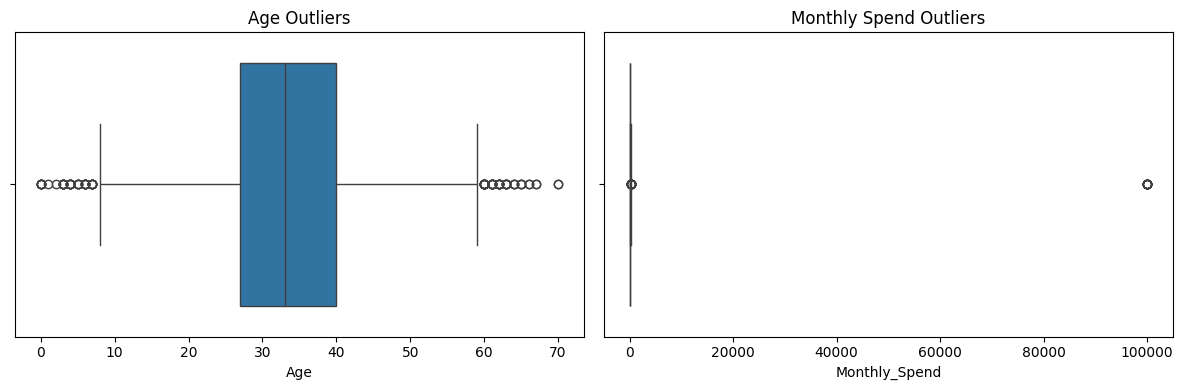

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=df["Age"])
plt.title("Age Outliers")

plt.subplot(1, 2, 2)
sns.boxplot(x=df["Monthly_Spend"])
plt.title("Monthly Spend Outliers")

plt.tight_layout()
plt.show()

In [10]:
# Cap upper Monthly_Spend outliers
df["Monthly_Spend"] = df["Monthly_Spend"].clip(
    upper=spend_upper
)

In [11]:
# Numerical columns: median imputation
df["Age"] = df["Age"].fillna(df["Age"].median())

df["Monthly_Spend"] = df["Monthly_Spend"].fillna(
    df["Monthly_Spend"].median()
)

df["Customer_Service_Calls"] = df[
    "Customer_Service_Calls"
].fillna(df["Customer_Service_Calls"].median())

# Categorical column
df["Payment_Method"] = df["Payment_Method"].fillna("Unknown")

print("Missing values after treatment:")
print(df.isnull().sum())

Missing values after treatment:
Customer_ID               0
Gender                    0
Region                    0
Subscription_Plan         0
Payment_Method            0
Age                       0
Days_Since_Last_Login     0
Customer_Service_Calls    0
Monthly_Spend             0
Churn                     0
dtype: int64


In [12]:
df["Customer_ID"] = df["Customer_ID"].astype("int64")

df["Age"] = df["Age"].round().astype("int64")

df["Days_Since_Last_Login"] = df[
    "Days_Since_Last_Login"
].astype("int64")

df["Customer_Service_Calls"] = df[
    "Customer_Service_Calls"
].round().astype("int64")

df["Churn"] = df["Churn"].astype("int64")

df["Monthly_Spend"] = df["Monthly_Spend"].astype("float64")

print(df.dtypes)

Customer_ID                 int64
Gender                     object
Region                     object
Subscription_Plan          object
Payment_Method             object
Age                         int64
Days_Since_Last_Login       int64
Customer_Service_Calls      int64
Monthly_Spend             float64
Churn                       int64
dtype: object


In [13]:
after_report = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Missing Cells",
        "Duplicate Rows"
    ],
    "After Cleaning": [
        len(df),
        len(df.columns),
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ]
})

comparison = before_report.merge(after_report, on="Metric")

display(comparison)

,Metric,Before Cleaning,After Cleaning
0,Total Rows,10300,10000
1,Total Columns,10,10
2,Missing Cells,2272,0
3,Duplicate Rows,300,0


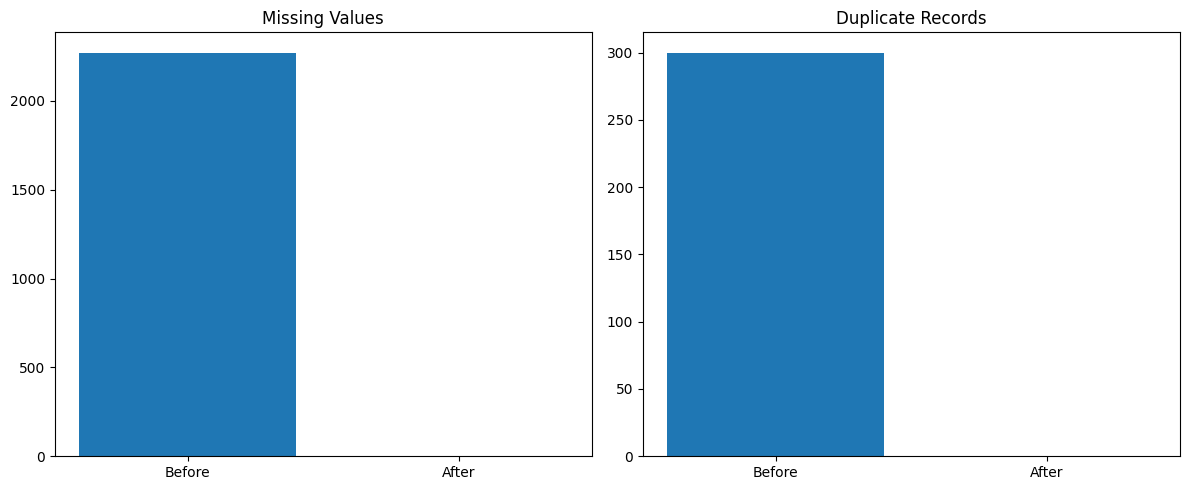

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(
    ["Before", "After"],
    [
        before_report.loc[2, "Before Cleaning"],
        after_report.loc[2, "After Cleaning"]
    ]
)
axes[0].set_title("Missing Values")

axes[1].bar(
    ["Before", "After"],
    [
        before_report.loc[3, "Before Cleaning"],
        after_report.loc[3, "After Cleaning"]
    ]
)
axes[1].set_title("Duplicate Records")

plt.tight_layout()
plt.show()

In [15]:
df.to_csv("customer_churn_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final shape:", df.shape)

Cleaned dataset saved successfully!
Final shape: (10000, 10)
